<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="300" alt="Skills Network Logo">
    </a>
</p>


# Test Environment for Generative AI classroom labs

This lab provides a test environment for the codes generated using the Generative AI classroom.

Follow the instructions below to set up this environment for further use.


# Setup


### Install required libraries

In case of a requirement of installing certain python libraries for use in your task, you may do so as shown below.


In [1]:
%pip install seaborn
import piplite

await piplite.install(['nbformat', 'plotly'])

### Dataset URL from the GenAI lab
Use the URL provided in the GenAI lab in the cell below. 


In [2]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod1.csv"

### Downloading the dataset

Execute the following code to download the dataset in to the interface.

> Please note that this step is essential in JupyterLite. If you are using a downloaded version of this notebook and running it on JupyterLabs, then you can skip this step and directly use the URL in pandas.read_csv() function to read the dataset as a dataframe


In [3]:
from pyodide.http import pyfetch

async def download(url, filename):
    response = await pyfetch(url)
    if response.status == 200:
        with open(filename, "wb") as f:
            f.write(await response.bytes())

path = URL

await download(path, "dataset.csv")
file_name  = "dataset.csv"

---


# Test Environment


In [4]:
# Data Preparation code generated by prompting GPT-5.4 Nano

In [5]:
# Importing the dataset
import pandas as pd

path = "dataset.csv"
df = pd.read_csv(path)
print(df.head())


<ipython-input-5-ad381b03c9fa>:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


   Unnamed: 0 Manufacturer  Category     Screen  GPU  OS  CPU_core  \
0           0         Acer         4  IPS Panel    2   1         5   
1           1         Dell         3    Full HD    1   1         3   
2           2         Dell         3    Full HD    1   1         7   
3           3         Dell         4  IPS Panel    2   1         5   
4           4           HP         4    Full HD    2   1         7   

   Screen_Size_cm  CPU_frequency  RAM_GB  Storage_GB_SSD  Weight_kg  Price  
0          35.560            1.6       8             256       1.60    978  
1          39.624            2.0       4             256       2.20    634  
2          39.624            2.7       8             256       2.20    946  
3          33.782            1.6       8             128       1.22   1244  
4          39.624            1.8       8             256       1.91    837  


In [6]:
#Handling missing data

missing_mask = df.isna()
missing_cols = missing_mask.any()

missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_cols]

print(missing_counts)

Screen_Size_cm    4
Weight_kg         5
dtype: int64


In [7]:
# Screen size is categorical, replace with most freqeuent
#Weight is numeric, replace with mean

df["Screen_Size_cm"] = df["Screen_Size_cm"].fillna(df["Screen_Size_cm"].mode().iloc[0])
df["Weight_kg"] = df["Weight_kg"].fillna(df["Weight_kg"].mean())

In [8]:
#Change data type for both variables to float

df["Screen_Size_cm"] = df["Screen_Size_cm"].astype(float)
df["Weight_kg"] = df["Weight_kg"].astype(float)

In [9]:
# Convert screen size to inches & modify name
# Convert weight to pounds & modify name

df["Screen_Size_inch"] = df["Screen_Size_cm"] / 2.54
df.drop(columns=["Screen_Size_cm"], inplace=True)

df["Weight_pounds"] = df["Weight_kg"] * 2.2046226218
df.drop(columns=["Weight_kg"], inplace=True)


In [10]:
# Normalise original data under CPU frequency w.r.t max values

df["CPU_frequency"] = df["CPU_frequency"] / df["CPU_frequency"].max()

In [11]:
# One-hot encode screen column

df1 = pd.get_dummies(df["Screen"], prefix="Screen")
df = pd.concat([df, df1], axis=1)
df.drop(columns=["Screen"], inplace=True)

In [12]:
# Convert price from USD to Euros
rate = 0.92  # USD -> EUR conversion rate
df["Price"] = df["Price"] * rate

In [13]:
#Normalise original data under CPU frequency w.r.t min-max values

min_v = df["CPU_frequency"].min()
max_v = df["CPU_frequency"].max()
df["CPU_frequency"] = (df["CPU_frequency"] - min_v) / (max_v - min_v)

In [14]:
# Drop irrelevant column

df.drop(columns=["Unnamed: 0"], inplace=True)

In [15]:
# Display cleaned data

df.head()

,Manufacturer,Category,GPU,OS,CPU_core,CPU_frequency,RAM_GB,Storage_GB_SSD,Price,Screen_Size_inch,Weight_pounds,Screen_Full HD,Screen_IPS Panel
0,Acer,4,2,1,5,0.235294,8,256,899.76,14.0,3.527396,False,True
1,Dell,3,1,1,3,0.470588,4,256,583.28,15.6,4.850170,True,False
2,Dell,3,1,1,7,0.882353,8,256,870.32,15.6,4.850170,True,False
3,Dell,4,2,1,5,0.235294,8,128,1144.48,13.3,2.689640,False,True
4,HP,4,2,1,7,0.352941,8,256,770.04,15.6,4.210829,True,False


In [16]:
# Data insights code generated by prompting GPT-5.4 Nano

In [17]:
# Statistical description of all features incl. object

description = df.describe(include="all")
print(description)

       Manufacturer    Category         GPU          OS    CPU_core  \
count           238  238.000000  238.000000  238.000000  238.000000   
unique           11         NaN         NaN         NaN         NaN   
top            Dell         NaN         NaN         NaN         NaN   
freq             71         NaN         NaN         NaN         NaN   
mean            NaN    3.205882    2.151261    1.058824    5.630252   
std             NaN    0.776533    0.638282    0.235790    1.241787   
min             NaN    1.000000    1.000000    1.000000    3.000000   
25%             NaN    3.000000    2.000000    1.000000    5.000000   
50%             NaN    3.000000    2.000000    1.000000    5.000000   
75%             NaN    4.000000    3.000000    1.000000    7.000000   
max             NaN    5.000000    3.000000    2.000000    7.000000   

        CPU_frequency      RAM_GB  Storage_GB_SSD        Price  \
count      238.000000  238.000000      238.000000   238.000000   
unique         

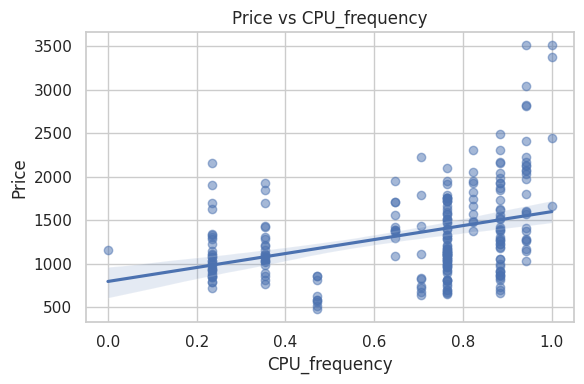

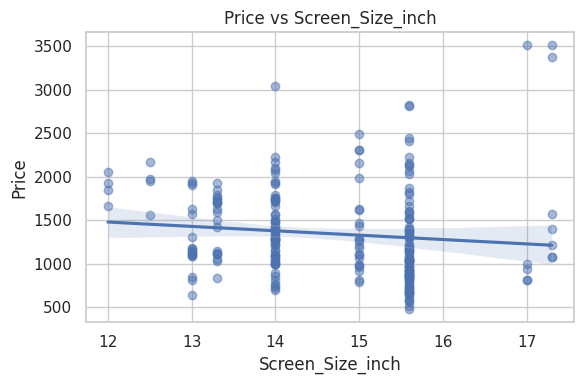

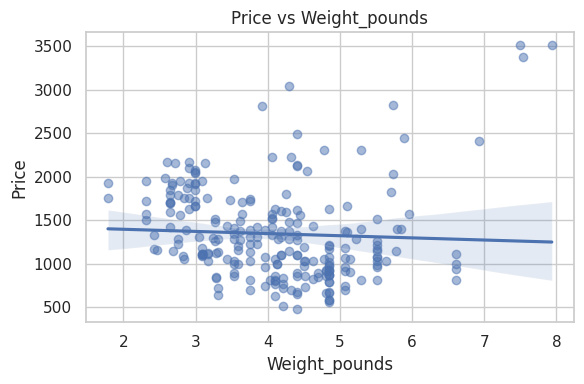

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set Seaborn aesthetics
sns.set(style='whitegrid')

# Regression plots: Price vs numeric attributes
plt.figure(figsize=(6, 4))
sns.regplot(x='CPU_frequency', y='Price', data=df, scatter_kws={'alpha': 0.5})
plt.title('Price vs CPU_frequency')
plt.xlabel('CPU_frequency')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.regplot(x='Screen_Size_inch', y='Price', data=df, scatter_kws={'alpha': 0.5})
plt.title('Price vs Screen_Size_inch')
plt.xlabel('Screen_Size_inch')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.regplot(x='Weight_pounds', y='Price', data=df, scatter_kws={'alpha': 0.5})
plt.title('Price vs Weight_pounds')
plt.xlabel('Weight_pounds')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

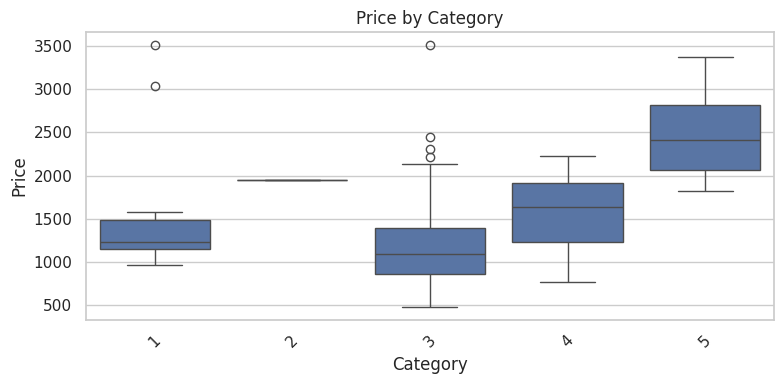

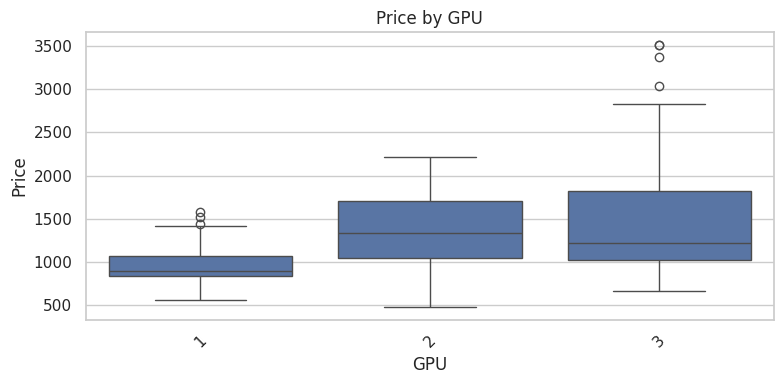

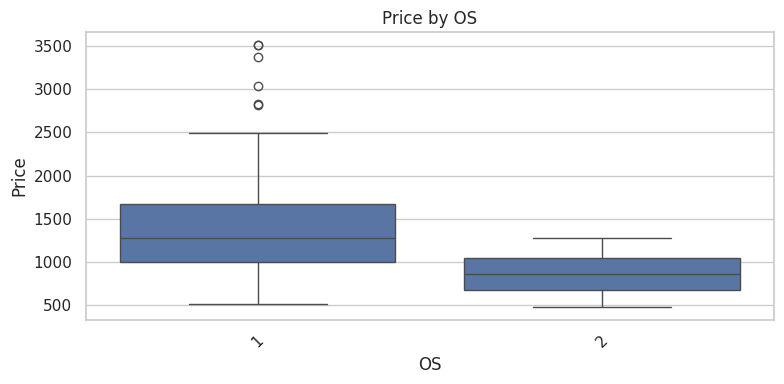

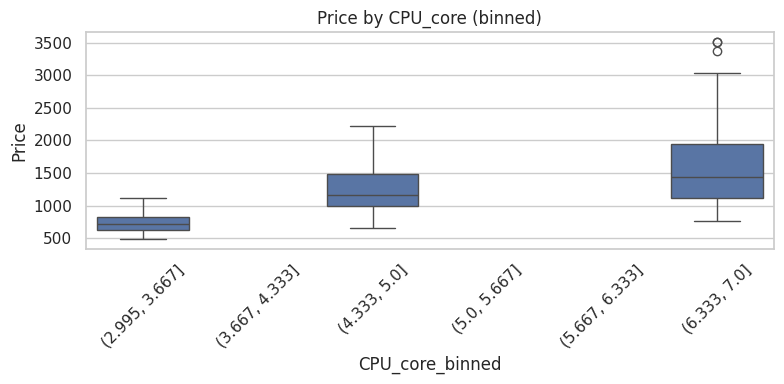

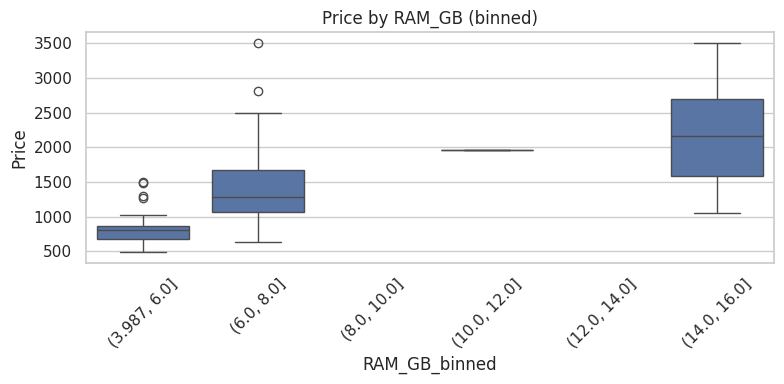

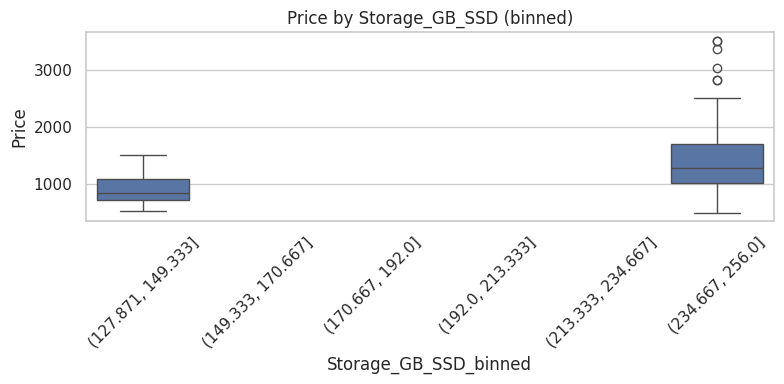

In [19]:
# Box plots: Price by categorical attributes
plt.figure(figsize=(8, 4))
sns.boxplot(x='Category', y='Price', data=df)
plt.xticks(rotation=45)
plt.title('Price by Category')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x='GPU', y='Price', data=df)
plt.xticks(rotation=45)
plt.title('Price by GPU')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x='OS', y='Price', data=df)
plt.xticks(rotation=45)
plt.title('Price by OS')
plt.tight_layout()
plt.show()

# For numeric attributes, create bins to enable box plots against Price
df['CPU_core_binned'] = pd.cut(df['CPU_core'], bins=6, include_lowest=True)
plt.figure(figsize=(8, 4))
sns.boxplot(x='CPU_core_binned', y='Price', data=df)
plt.xticks(rotation=45)
plt.title('Price by CPU_core (binned)')
plt.tight_layout()
plt.show()

df['RAM_GB_binned'] = pd.cut(df['RAM_GB'], bins=6, include_lowest=True)
plt.figure(figsize=(8, 4))
sns.boxplot(x='RAM_GB_binned', y='Price', data=df)
plt.xticks(rotation=45)
plt.title('Price by RAM_GB (binned)')
plt.tight_layout()
plt.show()

df['Storage_GB_SSD_binned'] = pd.cut(df['Storage_GB_SSD'], bins=6, include_lowest=True)
plt.figure(figsize=(8, 4))
sns.boxplot(x='Storage_GB_SSD_binned', y='Price', data=df)
plt.xticks(rotation=45)
plt.title('Price by Storage_GB_SSD (binned)')
plt.tight_layout()
plt.show()


In [20]:
# Evaluate dependencies
from scipy.stats import pearsonr

num_cols = df.select_dtypes(include="number").columns.tolist()
num_cols = [c for c in num_cols if c != "Price"]

rows = []
for c in num_cols:
    r, p = pearsonr(df[c], df["Price"])
    rows.append({"attribute": c, "pearson_r": r, "p_value": p})

result = pd.DataFrame(rows)
print(result)

          attribute  pearson_r       p_value
0          Category   0.286243  7.225696e-06
1               GPU   0.288298  6.166950e-06
2                OS  -0.221730  5.696643e-04
3          CPU_core   0.459398  7.912950e-14
4     CPU_frequency   0.366666  5.502463e-09
5            RAM_GB   0.549297  3.681561e-20
6    Storage_GB_SSD   0.243421  1.489892e-04
7  Screen_Size_inch  -0.110644  8.853398e-02
8     Weight_pounds  -0.050312  4.397694e-01


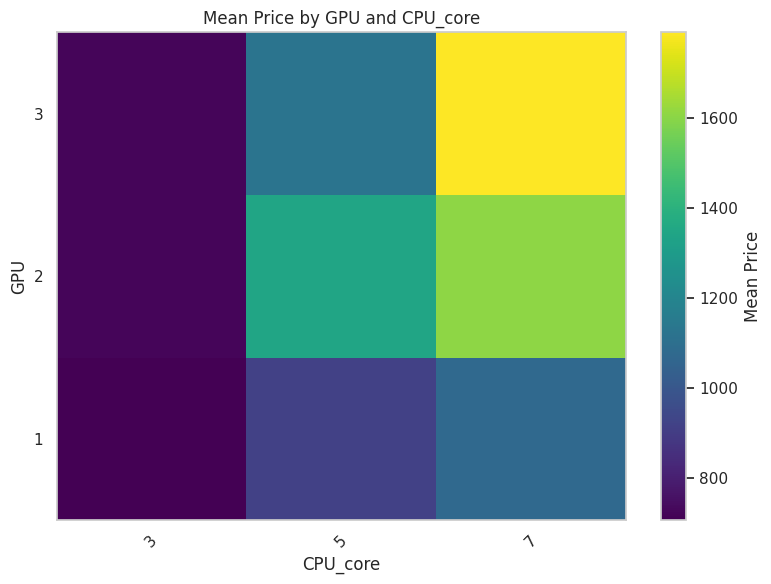

In [21]:
# Grouping attributes, creating and visualising a pivot table
import numpy as np

# Create a pivot table grouping by GPU (rows) and CPU_core (columns) with mean Price
pivot = df.pivot_table(values='Price', index='GPU', columns='CPU_core', aggfunc='mean')

# Plot a pcolor heatmap of the pivot table
plt.figure(figsize=(8, 6))
pc = plt.pcolor(pivot.values, cmap='viridis')
plt.colorbar(pc, label='Mean Price')
plt.xlabel('CPU_core')
plt.ylabel('GPU')
plt.title('Mean Price by GPU and CPU_core')

# Set axis tick labels
plt.xticks(np.arange(0.5, len(pivot.columns), 1), pivot.columns, rotation=45)
plt.yticks(np.arange(0.5, len(pivot.index), 1), pivot.index)
plt.tight_layout()
plt.show()



In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


source_col = "CPU_frequency"
target_col = "Price"

X = df[[source_col]]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R^2:", r2)


MSE: 202320.0655707467
R^2: -0.03719417833496497


In [26]:
target_col = "Price"
feature_cols = ["CPU_frequency", "RAM_GB", "Storage_GB_SSD", "CPU_core", "OS", "GPU", "Category"]

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R^2:", r2)

MSE: 142682.4051388942
R^2: 0.26853839463024765


In [27]:
from sklearn.preprocessing import PolynomialFeatures

source_column = "CPU_frequency"
target_column = "Price"

df = df[[source_column, target_column]].dropna()

X = df[[source_column]]
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

orders = [2, 3, 5]
results = []

for order in orders:
    polynomial = PolynomialFeatures(degree=order)

    X_train_poly = polynomial.fit_transform(X_train)
    X_test_poly = polynomial.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    predictions = model.predict(X_test_poly)

    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append([order, mse, r2])
    print("Order:", order)
    print("MSE:", mse)
    print("R^2:", r2)
    print()

comparison = pd.DataFrame(results, columns=["Order", "MSE", "R^2"])
comparison = comparison.sort_values("MSE")

print("Model comparison:")
print(comparison)

Order: 2
MSE: 166117.47841780767
R^2: 0.1483984495132229

Order: 3
MSE: 174289.02076817743
R^2: 0.10650702302563386

Order: 5
MSE: 175488.93953478461
R^2: 0.10035563732056818

Model comparison:
   Order            MSE       R^2
0      2  166117.478418  0.148398
1      3  174289.020768  0.106507
2      5  175488.939535  0.100356


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

target_col = "Price"
feature_cols = ["CPU_frequency", "RAM_GB", "Storage_GB_SSD", "CPU_core", "OS", "GPU", "Category"]

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Pipeline([
    ("scaling", StandardScaler()),
    ("polynomial_features", PolynomialFeatures(degree=2)),
    ("linear_regression", LinearRegression())
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MSE:", mse)
print("R^2:", r2)


MSE: 1.0214179558269286e+31
R^2: -4.43200514867181e+25


In [44]:
print(df.columns.tolist())

['Category', 'GPU', 'OS', 'CPU_core', 'CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'Price']


In [45]:
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge

target_col = "Price"
feature_cols = df.columns.drop(target_col).tolist()
poly_features_cols = feature_cols[:2]

X = df[feature_cols]
y = df[target_col]

preprocessor = ColumnTransformer(
    transformers=[
        ("poly", PolynomialFeatures(degree=2, include_bias=False), poly_features_cols),
        ("passthrough", "passthrough", [c for c in feature_cols if c not in poly_features_cols])
    ]
)

pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

param_grid = {
    "preprocessor__poly__degree": [2],
    "model__alpha": [0.0001,0.001,0.01, 0.1, 1, 10]
}

grid = GridSearchCV(pipe, param_grid, cv=4, scoring="neg_mean_squared_error", n_jobs=-1)
grid.fit(X, y)

best = grid.best_estimator_
y_pred = best.predict(X)
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("MSE:", mse)
print("R^2:", r2)
print("Best params:", grid.best_params_)

MSE: 144501.87229589905
R^2: 0.5604996710950221
Best params: {'model__alpha': 0.1, 'preprocessor__poly__degree': 2}


## Authors


[Abhishek Gagneja](https://www.linkedin.com/in/abhishek-gagneja-23051987/)


## Change Log


|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2023-12-10|0.1|Abhishek Gagneja|Initial Draft created|


Copyright © 2023 IBM Corporation. All rights reserved.
